# Chapter 3. Detection 결과 분석

## 3.1 Results 객체 구조

추론 결과는 `Results` 객체의 리스트로 반환됩니다.  
이미지 1장 = `Results` 객체 1개입니다.

In [1]:
%matplotlib inline

In [2]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS

model = YOLO("yolo26n.pt")
results = model(str(ASSETS / "bus.jpg"), verbose=False)

result = results[0]   # 첫 번째 이미지 결과

print("result 타입:", type(result))
print()
print("주요 속성:")
print(f"  result.boxes    → 탐지된 객체 정보  ({type(result.boxes)})")
print(f"  result.orig_img → 원본 이미지       (shape: {result.orig_img.shape})")
print(f"  result.names    → 클래스 이름       ({len(result.names)}가지)")

result 타입: <class 'ultralytics.engine.results.Results'>

주요 속성:
  result.boxes    → 탐지된 객체 정보  (<class 'ultralytics.engine.results.Boxes'>)
  result.orig_img → 원본 이미지       (shape: (1080, 810, 3))
  result.names    → 클래스 이름       (80가지)


## 3.2 boxes 속성

`result.boxes` 에는 탐지된 모든 객체의 정보가 담겨 있습니다.

In [3]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS

model = YOLO("yolo26n.pt")
results = model(str(ASSETS / "bus.jpg"), verbose=False)

boxes = results[0].boxes

print("탐지된 객체 수:", len(boxes))
print()
print("boxes 속성:")
print(f"  .xyxy  : 바운딩 박스 (x1, y1, x2, y2) - 픽셀 좌표")
print(f"           shape: {boxes.xyxy.shape}")
print()
print(f"  .xywh  : 바운딩 박스 (cx, cy, w, h) - 중심점 + 크기")
print(f"           shape: {boxes.xywh.shape}")
print()
print(f"  .xyxyn : 바운딩 박스 (x1, y1, x2, y2) - 정규화 (0~1)")
print(f"           shape: {boxes.xyxyn.shape}")
print()
print(f"  .conf  : 신뢰도 (0~1)   shape: {boxes.conf.shape}")
print(f"  .cls   : 클래스 ID       shape: {boxes.cls.shape}")

탐지된 객체 수: 5

boxes 속성:
  .xyxy  : 바운딩 박스 (x1, y1, x2, y2) - 픽셀 좌표
           shape: torch.Size([5, 4])

  .xywh  : 바운딩 박스 (cx, cy, w, h) - 중심점 + 크기
           shape: torch.Size([5, 4])

  .xyxyn : 바운딩 박스 (x1, y1, x2, y2) - 정규화 (0~1)
           shape: torch.Size([5, 4])

  .conf  : 신뢰도 (0~1)   shape: torch.Size([5])
  .cls   : 클래스 ID       shape: torch.Size([5])


## 3.3 각 객체 정보 출력

> 💡 **`.item()`과 `.tolist()`**: YOLO 결과값은 PyTorch 텐서(Tensor) 형식입니다.  
> 텐서는 GPU 연산용 특수 배열이라, 일반 파이썬 숫자/리스트로 변환해야 출력이나 계산에 쓸 수 있습니다.  
> - `.item()` → 텐서에서 파이썬 숫자(float/int)로 변환  
> - `.tolist()` → 텐서에서 파이썬 리스트로 변환

In [4]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS

model = YOLO("yolo26n.pt")
results = model(str(ASSETS / "bus.jpg"), verbose=False)
result = results[0]

print(f"{'번호':>4} {'클래스':>12} {'신뢰도':>8} {'x1':>8} {'y1':>8} {'x2':>8} {'y2':>8}")
print("-" * 60)

for i, box in enumerate(result.boxes):
    cls_id = int(box.cls[0].item())
    cls_name = result.names[cls_id]
    conf = box.conf[0].item()
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    
    print(f"[{i+1:2d}] {cls_name:>12} {conf:>8.2f} {x1:>8.1f} {y1:>8.1f} {x2:>8.1f} {y2:>8.1f}")

  번호          클래스      신뢰도       x1       y1       x2       y2
------------------------------------------------------------
[ 1]          bus     0.88      0.0    230.5    803.2    750.7
[ 2]       person     0.87     48.6    397.7    240.3    902.4
[ 3]       person     0.86    222.9    404.8    345.5    861.0
[ 4]       person     0.85    669.6    394.5    809.9    879.4
[ 5]       person     0.66      0.2    552.9     59.7    871.3


## 3.4 COCO 80 클래스

YOLO26 Detection은 COCO 데이터셋의 **80가지 일상 객체**를 탐지합니다.

In [5]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")
names = model.names

print(f"총 클래스 수: {len(names)}")
print()

# 카테고리별로 보기
# COCO 클래스 인덱스는 0부터 시작합니다.
# 전체 목록은 아래 "전체 클래스 출력" 코드로 확인할 수 있습니다.
categories = {
    "사람": list(range(0, 1)),   # 0: person
    "탈것": list(range(1, 9)),   # 1~8: bicycle, car, motorcycle, airplane, bus, train, truck, boat
    "동물": list(range(14, 24)),
    "음식": list(range(46, 56)),
    "전자기기": list(range(62, 68)),
}

for category, indices in categories.items():
    items = [names[i] for i in indices if i in names]
    print(f"{category}: {', '.join(items)}")

총 클래스 수: 80

사람: person
탈것: bicycle, car, motorcycle, airplane, bus, train, truck, boat
동물: bird, cat, dog, horse, sheep, cow, elephant, bear, zebra, giraffe
음식: banana, apple, sandwich, orange, broccoli, carrot, hot dog, pizza, donut, cake
전자기기: tv, laptop, mouse, remote, keyboard, cell phone


In [6]:
# 전체 클래스 출력
from ultralytics import YOLO

model = YOLO("yolo26n.pt")

print("COCO 80 클래스 전체 목록:")
for idx, name in model.names.items():
    print(f"  [{idx:2d}] {name}")

COCO 80 클래스 전체 목록:
  [ 0] person
  [ 1] bicycle
  [ 2] car
  [ 3] motorcycle
  [ 4] airplane
  [ 5] bus
  [ 6] train
  [ 7] truck
  [ 8] boat
  [ 9] traffic light
  [10] fire hydrant
  [11] stop sign
  [12] parking meter
  [13] bench
  [14] bird
  [15] cat
  [16] dog
  [17] horse
  [18] sheep
  [19] cow
  [20] elephant
  [21] bear
  [22] zebra
  [23] giraffe
  [24] backpack
  [25] umbrella
  [26] handbag
  [27] tie
  [28] suitcase
  [29] frisbee
  [30] skis
  [31] snowboard
  [32] sports ball
  [33] kite
  [34] baseball bat
  [35] baseball glove
  [36] skateboard
  [37] surfboard
  [38] tennis racket
  [39] bottle
  [40] wine glass
  [41] cup
  [42] fork
  [43] knife
  [44] spoon
  [45] bowl
  [46] banana
  [47] apple
  [48] sandwich
  [49] orange
  [50] broccoli
  [51] carrot
  [52] hot dog
  [53] pizza
  [54] donut
  [55] cake
  [56] chair
  [57] couch
  [58] potted plant
  [59] bed
  [60] dining table
  [61] toilet
  [62] tv
  [63] laptop
  [64] mouse
  [65] remote
  [66] keyboard
 

## 3.5 클래스별 필터링

특정 클래스만 탐지하고 싶을 때 `classes` 파라미터를 사용합니다.

전체 탐지: 5개
사람만: 4명
버스+트럭: 1대


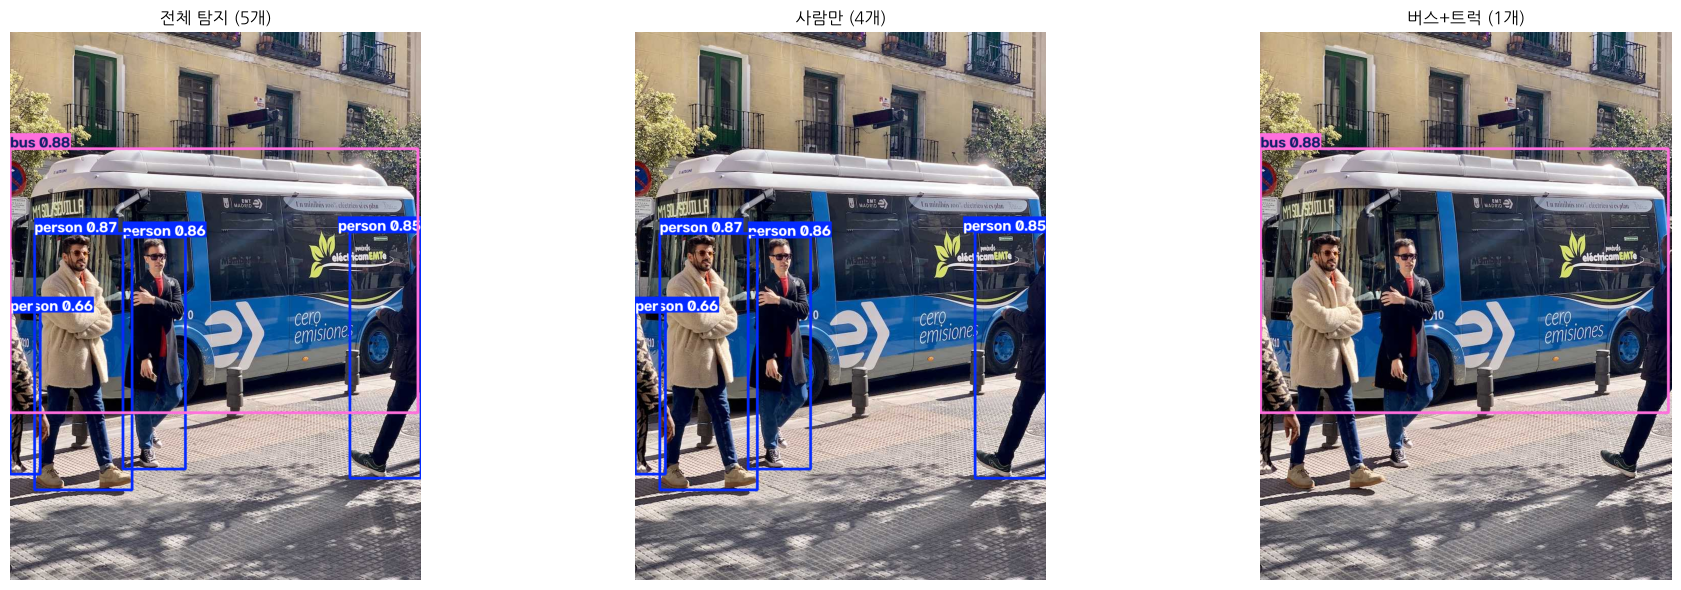

In [7]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS
import matplotlib.pyplot as plt
import koreanize_matplotlib

model = YOLO("yolo26n.pt")
image_path = str(ASSETS / "bus.jpg")

# 전체 탐지
results_all = model(image_path, verbose=False)
print(f"전체 탐지: {len(results_all[0].boxes)}개")

# 사람(0)만 탐지
results_person = model(image_path, classes=[0], verbose=False)
print(f"사람만: {len(results_person[0].boxes)}명")

# 버스(5), 트럭(7)만 탐지
results_vehicle = model(image_path, classes=[5, 7], verbose=False)
print(f"버스+트럭: {len(results_vehicle[0].boxes)}대")

# 시각화 비교
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, result, title in zip(
    axes,
    [results_all[0], results_person[0], results_vehicle[0]],
    ["전체 탐지", "사람만", "버스+트럭"]
):
    ax.imshow(result.plot()[..., ::-1])
    ax.set_title(f"{title} ({len(result.boxes)}개)", fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3.6 신뢰도(confidence)에 따른 탐지 변화

| conf 값 | 효과 |
|---------|------|
| 낮게 (0.1) | 더 많이 탐지, 오탐지 가능성 높음 |
| 기본값 (0.25) | 균형 잡힌 탐지 |
| 높게 (0.5~) | 확실한 것만 탐지, 누락 가능성 있음 |

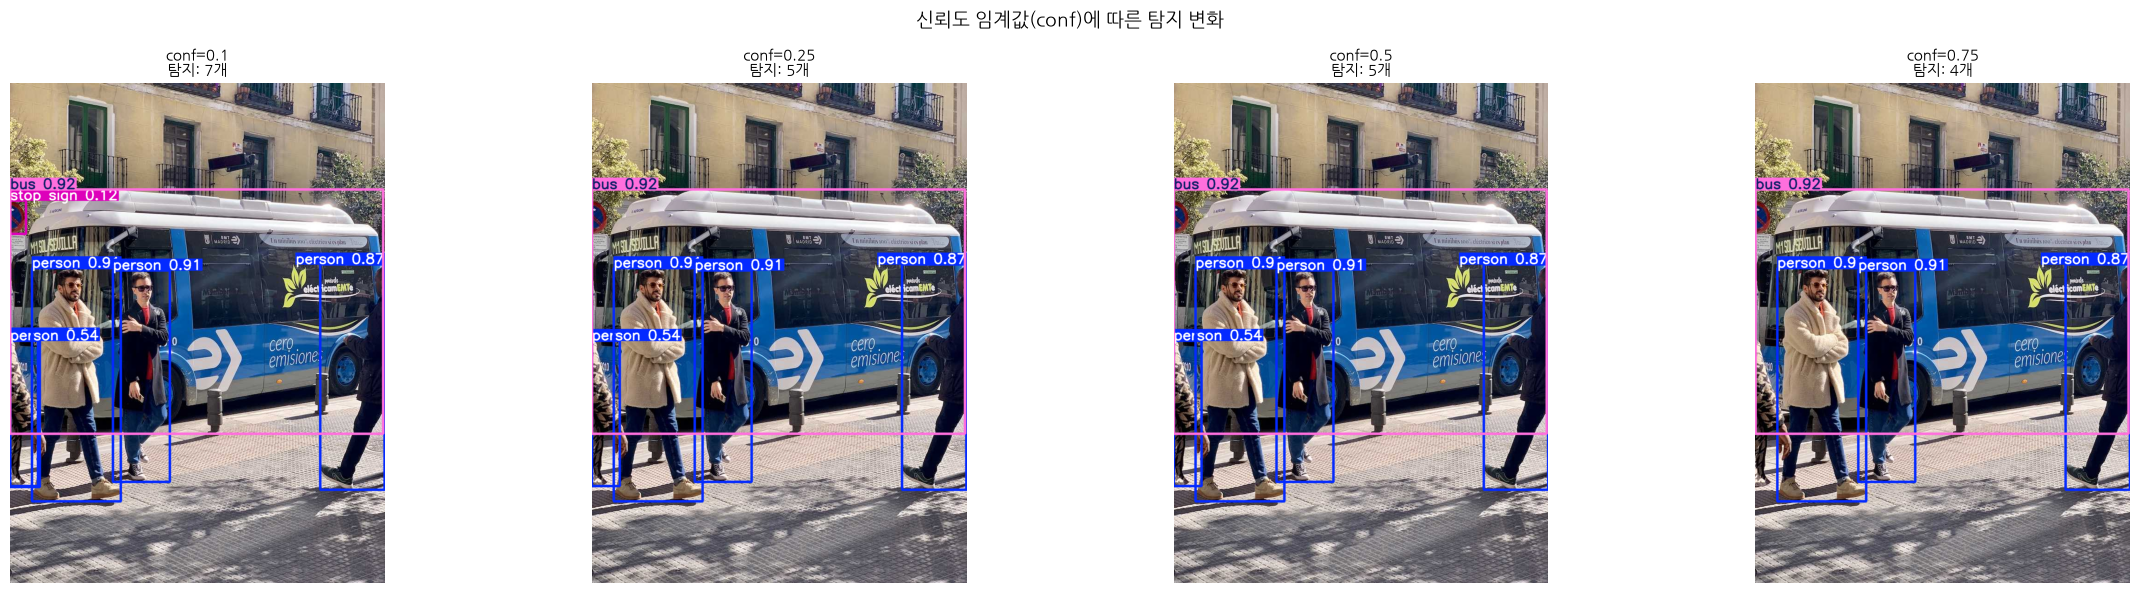

In [8]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS
import matplotlib.pyplot as plt
import koreanize_matplotlib

model = YOLO("yolo26n.pt")
image_path = str(ASSETS / "bus.jpg")

conf_values = [0.1, 0.25, 0.5, 0.75]

fig, axes = plt.subplots(1, 4, figsize=(24, 6))

for ax, conf in zip(axes, conf_values):
    results = model(image_path, conf=conf, verbose=False)
    ax.imshow(results[0].plot()[..., ::-1])
    ax.set_title(f"conf={conf}\n탐지: {len(results[0].boxes)}개", fontsize=11)
    ax.axis("off")

plt.suptitle("신뢰도 임계값(conf)에 따른 탐지 변화", fontsize=14)
plt.tight_layout()
plt.show()

## 3.7 바운딩 박스 직접 그리기

OpenCV로 원하는 스타일로 바운딩 박스를 그립니다.

> 💡 **OpenCV 주요 함수**:
> - `cv2.rectangle(img, (x1,y1), (x2,y2), color, thickness)` — 사각형 그리기. thickness=-1이면 채워진 사각형
> - `cv2.putText(img, text, (x,y), font, scale, color, thickness)` — 텍스트 그리기
> - `cv2.getTextSize(text, font, scale, thickness)` — 텍스트 크기 미리 계산 (배경 박스 크기 결정에 사용)

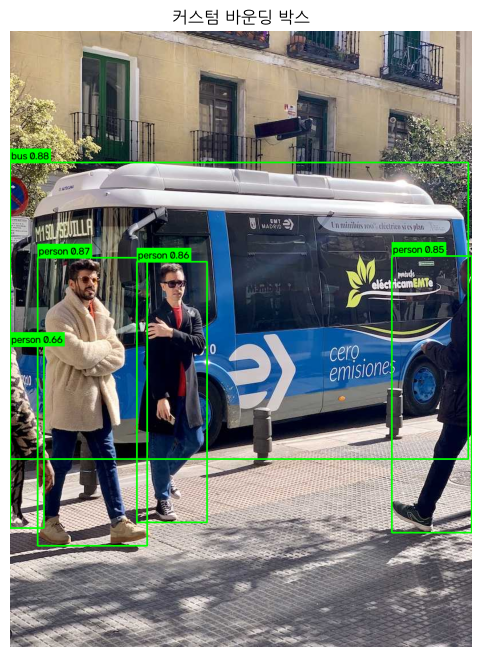

In [8]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS
import cv2
import matplotlib.pyplot as plt
import koreanize_matplotlib

model = YOLO("yolo26n.pt")
results = model(str(ASSETS / "bus.jpg"), verbose=False)
result = results[0]

img = result.orig_img.copy()

for box in result.boxes:
    cls_id = int(box.cls[0].item())
    cls_name = result.names[cls_id]
    conf = box.conf[0].item()
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    
    # 바운딩 박스 그리기
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    
    # 레이블 배경 + 텍스트
    label = f"{cls_name} {conf:.2f}"
    (w, h), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
    cv2.rectangle(img, (x1, y1 - h - 8), (x1 + w + 4, y1), (0, 255, 0), -1)
    cv2.putText(img, label, (x1 + 2, y1 - 5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 1)

plt.figure(figsize=(12, 8))
plt.imshow(img[..., ::-1])
plt.axis("off")
plt.title("커스텀 바운딩 박스")
plt.show()

## 3.8 탐지 결과 집계

> 💡 **Counter**: 파이썬 기본 라이브러리 `collections`에 포함된 클래스입니다. 항목의 개수를 자동으로 세어 딕셔너리처럼 사용할 수 있습니다.

In [10]:
from ultralytics import YOLO
from ultralytics.utils import ASSETS
from collections import Counter

model = YOLO("yolo26n.pt")
results = model(str(ASSETS / "bus.jpg"), verbose=False)
result = results[0]

# 클래스별 탐지 수 집계
cls_counts = Counter()
for box in result.boxes:
    cls_id = int(box.cls[0].item())
    cls_name = result.names[cls_id]
    cls_counts[cls_name] += 1

print("클래스별 탐지 결과:")
for cls_name, count in cls_counts.most_common():
    print(f"  {cls_name}: {count}개")

클래스별 탐지 결과:
  person: 4개
  bus: 1개


## 3.9 정리

- `result.boxes` 에서 탐지된 객체 정보를 가져옵니다
- `boxes.xyxy` → 픽셀 좌표 바운딩 박스, `boxes.conf` → 신뢰도, `boxes.cls` → 클래스 ID
- `result.names[cls_id]` 로 클래스 이름을 가져옵니다
- `classes=[0, 5]` 파라미터로 특정 클래스만 필터링합니다